# Lens refraction and stigmatic focusing

Compare a plano-convex lens with a matched Cartesian-oval exit face using the current **spectral or local Fresnel propagation operator**. Both receive the same beam and are observed on the same coordinates. We retain meridional maps, focal components, polarization, an optical-cycle animation.

The sequence is homogeneous propagation → surface trace $Q$ → the selected Fresnel transmission $T$ → outgoing surface-equivalence reconstruction → homogeneous propagation. `SurfaceTransport.inverse` is a separate least-squares operation; it is not used implicitly here. Geometrical rays below are explanatory overlays, not directions inferred from the coherent field.

**Model:** open dielectric graph surfaces illuminated by a smooth, compact beam. The illumination radius is not a material rim or a stop. The current pipeline does not solve either. Returning reflections are omitted. To keep the *whole* FFT chart within both shapes and prevent chart intersections, this migrated example uses curvature $120\lambda_0$, thickness $64\lambda_0$ and a $128\lambda_0$ cell; these replace the former finite-edge geometry. Old numerical conclusions are recomputed rather than carried over.

The transport band is explicitly `max_sine=0.95`, covering the corner of the default directional square (0.65 per transverse component). Omitted modal norms are printed; this does not imply that evanescent input modes are retained.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
um = 1e-6
wavelength = 532e-9


transmission = (
    "spectral"  # Change to "local" to use internally estimated phase gradients.
)

In [2]:
air = optics.HomogeneousRegion("entrance air", optics.Dielectric(1))
glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
exit_air = optics.HomogeneousRegion("exit air", optics.Dielectric(1))
radius, thickness = 120 * wavelength, 64 * wavelength
illumination_radius, waist = 48 * wavelength, 48 * wavelength
front = optics.Plane()
back = optics.SphericalCap(-radius, optics.Frame([0, 0, thickness]))
focal_distance = radius / (glass.material.n - exit_air.material.n)
image_z = thickness + focal_distance
oval = optics.CartesianOval.from_conjugates(
    1.5, -np.inf, 1, focal_distance, frame=back.frame
)


def illumination(grid, polarization=(1, 0)):
    rho = np.linalg.norm(grid.points[..., :2], axis=-1)
    taper = (
        np.cos(np.pi / 2 * np.clip((rho - 40 * wavelength) / (8 * wavelength), 0, 1))
        ** 4
    )
    envelope = np.exp(-((rho / waist) ** 2)) * taper
    values = envelope[..., None] * np.asarray(polarization)
    return optics.TransverseElectricField(grid, wavelength, values)


def lens_solution(exit_surface, count=128, width=128 * wavelength, polarization=(1, 0)):
    axis = (np.arange(count) - count // 2) * width / count
    grid = optics.CartesianGrid(axis, axis)
    source = illumination(grid, polarization)
    system = optics.OpticalSystem(
        [
            optics.DielectricInterface(front, air, glass),
            optics.DielectricInterface(exit_surface, glass, exit_air),
        ]
    )
    path = optics.PropagationPipeline(system, transmission=transmission, max_sine=0.95)
    tick = perf_counter()
    path(
        source,
        z=image_z,
        window=(-12 * wavelength, 12 * wavelength, -12 * wavelength, 12 * wavelength),
        shape=(121, 121),
    )
    result = path.last_solution
    seconds = perf_counter() - tick
    return result, seconds, source


solutions = {}
for label, surface in [("Spherical", back), ("Stigmatic", oval)]:
    result, seconds, source = lens_solution(surface)
    solutions[label] = result
    print(
        f"{label}: {transmission}, prepare + propagate + electric focal field {seconds:.3f} s"
    )

Spherical: spectral, prepare + propagate + electric focal field 3.829 s


Stigmatic: spectral, prepare + propagate + electric focal field 3.729 s


## Geometry and nominal Snell rays

These rays describe collimated incidence at the exit face. The actual pipeline keeps all incident angular components. Stigmatism concerns this nominal ray family; diffraction may shift the intensity maximum.

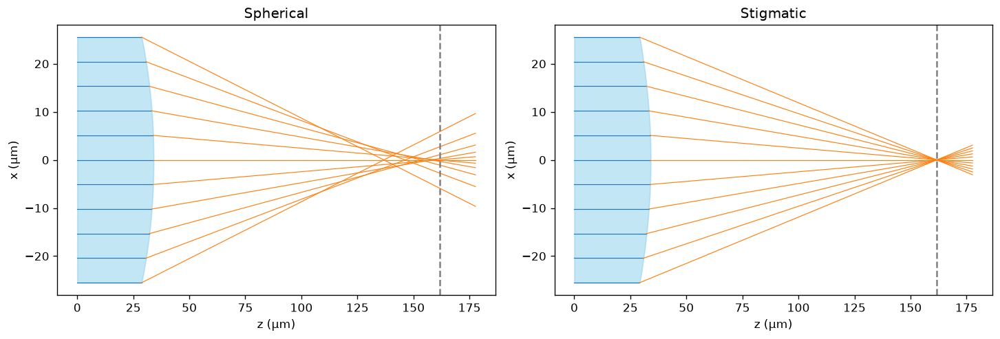

Nominal oval optical-path spread: 1.019e-13 wavelengths


In [3]:
from vecdiff_general.propagation._directions import transmitted_direction

meridian = np.linspace(-illumination_radius, illumination_radius, 201)
xy = np.column_stack((meridian, np.zeros_like(meridian)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, label, surface in zip(axes, solutions, [back, oval]):
    points, normals = surface.points(xy), surface.normals(xy)
    rays = transmitted_direction([0, 0, 1], normals, 1.5, 1).real
    ax.fill_betweenx(meridian / um, 0, points[:, 2] / um, color="skyblue", alpha=0.5)
    for p, d in zip(points[::20], rays[::20]):
        z_end = image_z + 30 * wavelength
        ax.plot([0, p[2] / um], [p[0] / um] * 2, color="tab:blue", lw=0.7)
        ax.plot(
            [p[2] / um, z_end / um],
            [p[0] / um, (p[0] + (z_end - p[2]) * d[0] / d[2]) / um],
            color="tab:orange",
            lw=0.7,
        )
    ax.axvline(image_z / um, ls="--", color="gray")
    ax.set(xlabel="z (µm)", ylabel="x (µm)", title=label)
plt.show()
points = oval.points(xy)
path = 1.5 * (points[:, 2] - thickness) + np.linalg.norm(
    points - [0, 0, image_z], axis=-1
)
path_spread = np.ptp(path) / wavelength
print(f"Nominal oval optical-path spread: {path_spread:.3e} wavelengths")
assert path_spread < 1e-10

## Follow the field through focus

Both solutions are evaluated on a common meridional section. Each column has a shared color scale; there is no fitted gain or displacement. The detector coordinate used below is the common geometrical image, not a separately optimized focus for each shape.

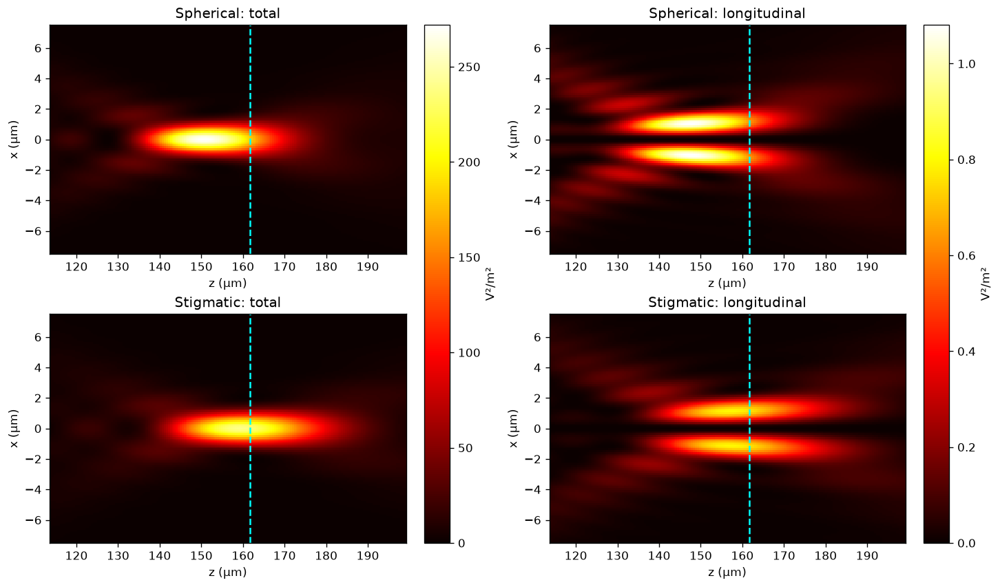

Spherical: sampled axial peak z = 150.7333 µm
Stigmatic: sampled axial peak z = 159.2453 µm


In [4]:
x = np.linspace(-14, 14, 121) * wavelength
z = thickness + np.linspace(150, 310, 181) * wavelength
X, Z = np.meshgrid(x, z)
section_grid = optics.PointGrid(np.stack((X, np.zeros_like(X), Z), axis=-1))
sections = {label: sol.field(section_grid) for label, sol in solutions.items()}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for col, component in enumerate(["total", "longitudinal"]):
    maps = [f.norm2() if col == 0 else abs(f.Ez) ** 2 for f in sections.values()]
    for row, (label, values) in enumerate(zip(sections, maps)):
        im = axes[row, col].pcolormesh(
            z / um,
            x / um,
            values.T,
            cmap="hot",
            vmin=0,
            vmax=max(v.max() for v in maps),
            shading="auto",
        )
        axes[row, col].axvline(image_z / um, color="cyan", ls="--")
        axes[row, col].set(
            xlabel="z (µm)", ylabel="x (µm)", title=f"{label}: {component}"
        )
    fig.colorbar(im, ax=axes[:, col], label="V²/m²")
plt.show()
for label, f in sections.items():
    peak_z = z[np.argmax(f.norm2()[:, len(x) // 2])]
    print(f"{label}: sampled axial peak z = {peak_z / um:.4f} µm")

## Focal components and collected power

The same physical detector receives both fields. Electric norm squared and normal Poynting flux have different units. Integrating the latter over a detector disk gives collected power; this is not a claim of global boundary energy conservation.

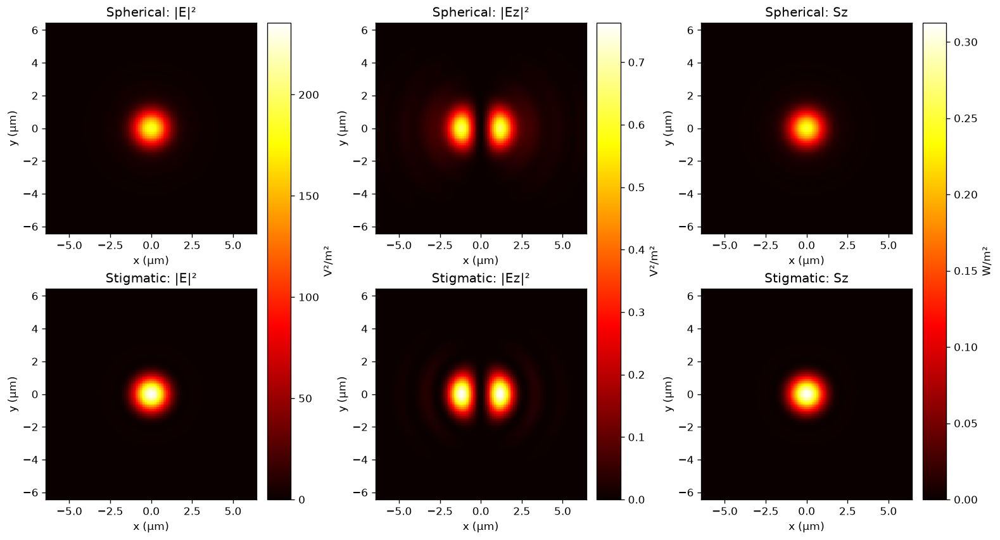

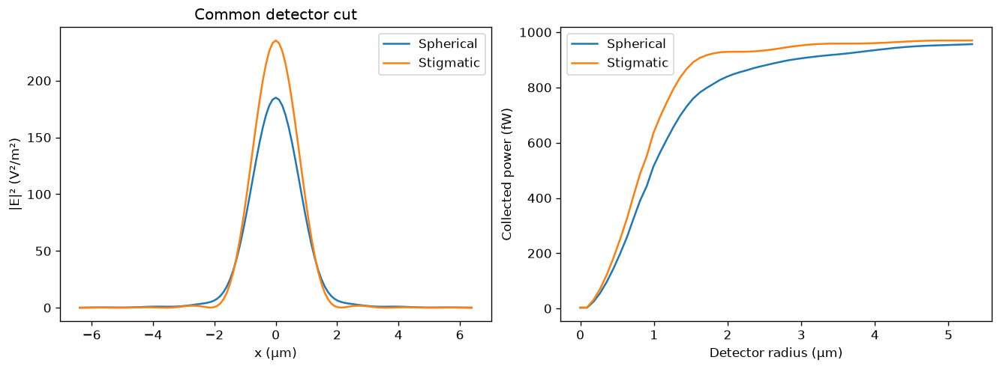

In [5]:
# E/H is requested here specifically for the Poynting-flux plots.
focal_axis = np.linspace(-12, 12, 121) * wavelength
focal_grid = optics.CartesianGrid(focal_axis, focal_axis, optics.Frame([0, 0, image_z]))
fields = {label: sol.evaluate(focal_grid) for label, sol in solutions.items()}
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for col, observable in enumerate(["|E|²", "|Ez|²", "Sz"]):
    values = [
        (f.electric.norm2(), abs(f.electric.Ez) ** 2, f.poynting()[..., 2])[col]
        for f in fields.values()
    ]
    for row, (label, v) in enumerate(zip(fields, values)):
        im = axes[row, col].pcolormesh(
            focal_axis / um,
            focal_axis / um,
            v,
            cmap="hot",
            vmin=min(0, min(a.min() for a in values)),
            vmax=max(a.max() for a in values),
            shading="auto",
        )
        axes[row, col].set(
            xlabel="x (µm)",
            ylabel="y (µm)",
            title=f"{label}: {observable}",
            aspect="equal",
        )
    fig.colorbar(im, ax=axes[:, col], label="W/m²" if col == 2 else "V²/m²")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
radii = np.linspace(0, 10, 60) * wavelength
rho = np.linalg.norm(focal_grid.points[..., :2], axis=-1)
for label, f in fields.items():
    axes[0].plot(focal_axis / um, f.electric.norm2()[len(focal_axis) // 2], label=label)
    power = [(f.poynting()[..., 2] * focal_grid.weights)[rho <= r].sum() for r in radii]
    axes[1].plot(radii / um, np.asarray(power) * 1e15, label=label)
axes[0].set(xlabel="x (µm)", ylabel="|E|² (V²/m²)", title="Common detector cut")
axes[1].set(xlabel="Detector radius (µm)", ylabel="Collected power (fW)")
for ax in axes:
    ax.legend()
plt.show()

## Polarization and an optical cycle

The first panels retain the linearly polarized comparison. A circular input is then propagated through the same oval lens, with equal input electric norm. Ellipses and moving vectors show the local transverse field; longitudinal components remain in the computed E/H.

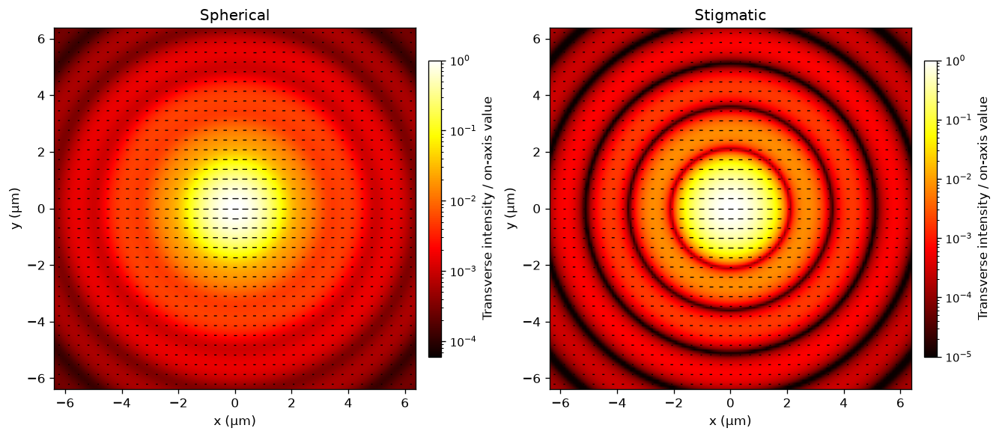

Circular-input solve: 3.451 s


In [6]:
from IPython.display import HTML, display
from vecdiff_general.visualization import animate_polarization, plot_focal_polarization

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, (label, f) in zip(axes, fields.items()):
    plot_focal_polarization(f, axis=ax, title=label)
plt.show()
circular, seconds, _ = lens_solution(oval, polarization=np.array([1, 1j]) / np.sqrt(2))
small_axis = np.linspace(-8, 8, 65) * wavelength
circular_field = circular.field(
    optics.CartesianGrid(small_axis, small_axis, optics.Frame([0, 0, image_z]))
)
print(f"Circular-input solve: {seconds:.3f} s")
animation = animate_polarization(
    circular_field,
    distribution="polar",
    frames=24,
    crop=False,
    figsize=(5, 4),
    title="Stigmatic focus: one optical cycle",
)
display(HTML(animation.to_jshtml()))
plt.close(animation._fig)